# California Housing: Model Selection and Hyperparameter Optimization

This notebook compares leakage-safe and leakage-prone preprocessing, tunes Random Forest with grid and randomized search, and optimizes Gradient Boosting with Optuna. All reported model-selection scores use 5-fold cross-validation. The target is median house value (in units of $100,000).

## 1. Imports and data
We use the California Housing dataset from scikit-learn. A fixed seed makes the searches reproducible.

In [5]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import KFold, cross_validate, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import randint, uniform

RANDOM_STATE = 42
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target
print(f'Features: {X.shape}; target: {y.shape}')
display(X.head())

Features: (20640, 8); target: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


## 2. StandardScaler and Random Forest with 5-fold cross-validation
The scaler is inside the pipeline, so each fold learns scaling statistics from its training portion only. We report RMSE and R²; lower RMSE and higher R² are better.

In [6]:
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1))
])
cv_results = cross_validate(
    rf_pipeline, X, y, cv=cv,
    scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
    n_jobs=-1
)
pipeline_rmse = -cv_results['test_rmse']
pipeline_r2 = cv_results['test_r2']
print(f'Pipeline 5-fold RMSE: {pipeline_rmse.mean():.4f} ± {pipeline_rmse.std():.4f}')
print(f'Pipeline 5-fold R²:   {pipeline_r2.mean():.4f} ± {pipeline_r2.std():.4f}')

Pipeline 5-fold RMSE: 0.5015 ± 0.0094
Pipeline 5-fold R²:   0.8110 ± 0.0073


## 3. Demonstrating preprocessing leakage
For comparison, this intentionally incorrect workflow fits `StandardScaler` on the complete dataset before cross-validation. Information from each validation fold therefore contributes to the scaling statistics. The pipeline above avoids this leakage. Since scaling does not materially change tree split ordering, Random Forest scores may be almost identical; the important distinction is that only the pipeline is methodologically safe and remains correct when preprocessing is data-dependent or the estimator is scale-sensitive.

In [7]:
X_scaled_before_cv = StandardScaler().fit_transform(X)  # Intentional leakage for demonstration
leaky_rf = RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)
leaky_scores = cross_validate(
    leaky_rf, X_scaled_before_cv, y, cv=cv,
    scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
    n_jobs=-1
)
comparison = pd.DataFrame({
    'Workflow': ['Pipeline (safe)', 'Scale before CV (leaky)'],
    'Mean RMSE': [pipeline_rmse.mean(), -leaky_scores['test_rmse'].mean()],
    'RMSE SD': [pipeline_rmse.std(), (-leaky_scores['test_rmse']).std()],
    'Mean R²': [pipeline_r2.mean(), leaky_scores['test_r2'].mean()]
})
display(comparison)
print('The leaky score difference is not evidence that leakage is harmless; it reflects the scale invariance of this tree-based model.')

,Workflow,Mean RMSE,RMSE SD,Mean R²
0,Pipeline (safe),0.501507,0.009434,0.810975
1,Scale before CV (leaky),0.501507,0.009328,0.810976


The leaky score difference is not evidence that leakage is harmless; it reflects the scale invariance of this tree-based model.


## 4. GridSearchCV for Random Forest
We search three hyperparameters: number of trees, maximum depth, and minimum samples per leaf. `neg_root_mean_squared_error` is maximized by scikit-learn, so the best score is converted back to RMSE for reporting.

In [8]:
rf_search_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
])
grid_params = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 15, 25],
    'model__min_samples_leaf': [1, 2, 4]
}
grid_search = GridSearchCV(
    rf_search_pipeline, grid_params, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X, y)
grid_best_rmse = -grid_search.best_score_
print('GridSearch best parameters:', grid_search.best_params_)
print(f'GridSearch best CV RMSE: {grid_best_rmse:.4f}')

GridSearch best parameters: {'model__max_depth': 25, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
GridSearch best CV RMSE: 0.5005


## 5. RandomizedSearchCV (50 iterations)
Randomized search samples from broader parameter ranges. It evaluates exactly 50 parameter combinations with the same 5-fold split strategy and scoring metric as grid search.

In [9]:
random_distributions = {
    'model__n_estimators': randint(100, 401),
    'model__max_depth': [None, 10, 15, 20, 25, 30],
    'model__min_samples_split': randint(2, 16),
    'model__min_samples_leaf': randint(1, 9),
    'model__max_features': [1.0, 'sqrt', 0.8]
}
random_search = RandomizedSearchCV(
    rf_search_pipeline, random_distributions, n_iter=50, cv=cv,
    scoring='neg_root_mean_squared_error', n_jobs=-1,
    random_state=RANDOM_STATE, return_train_score=True
)
random_search.fit(X, y)
random_best_rmse = -random_search.best_score_
print('RandomizedSearch best parameters:', random_search.best_params_)
print(f'RandomizedSearch best CV RMSE: {random_best_rmse:.4f}')
print(f'GridSearch CV RMSE: {grid_best_rmse:.4f}; RandomizedSearch CV RMSE: {random_best_rmse:.4f}')

RandomizedSearch best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 8, 'model__n_estimators': 161}
RandomizedSearch best CV RMSE: 0.4964
GridSearch CV RMSE: 0.5005; RandomizedSearch CV RMSE: 0.4964


## 6. Optuna optimization for Gradient Boosting (100 trials)
Each trial evaluates a Gradient Boosting model with 5-fold cross-validation. Install Optuna with `pip install optuna` if it is not available. The objective minimizes mean RMSE.

In [10]:
import optuna
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 2, 5),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 0.8]),
        'loss': 'squared_error',
        'random_state': RANDOM_STATE
    }
    model = Pipeline([('scaler', StandardScaler()), ('model', GradientBoostingRegressor(**params))])
    scores = cross_val_score(model, X, y, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return float(-scores.mean())

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=100, show_progress_bar=True)
optuna_best_rmse = study.best_value
print('Optuna best parameters:', study.best_params)
print(f'Optuna best 5-fold CV RMSE: {optuna_best_rmse:.4f}')

[I 2026-10-11 20:05:38,484] A new study created in memory with name: no-name-cff5ce5c-dedc-4ac6-820c-5b8a9b4dccd6


  0%|          | 0/100 [00:00<?, ?it/s]

[I 2026-10-11 20:05:43,715] Trial 0 finished with value: 0.4968676943887549 and parameters: {'n_estimators': 144, 'learning_rate': 0.17254716573280354, 'max_depth': 4, 'min_samples_split': 13, 'min_samples_leaf': 2, 'subsample': 0.662397808134481, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.4968676943887549.
[I 2026-10-11 20:06:08,395] Trial 1 finished with value: 0.5846090511328981 and parameters: {'n_estimators': 227, 'learning_rate': 0.010636066512540286, 'max_depth': 5, 'min_samples_split': 17, 'min_samples_leaf': 3, 'subsample': 0.6727299868828402, 'max_features': 0.8}. Best is trial 0 with value: 0.4968676943887549.
[I 2026-10-11 20:06:14,286] Trial 2 finished with value: 0.5875198854091754 and parameters: {'n_estimators': 158, 'learning_rate': 0.023927528765580644, 'max_depth': 4, 'min_samples_split': 4, 'min_samples_leaf': 3, 'subsample': 0.7465447373174767, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.4968676943887549.
[I 2026-10-11 20:06:18,098] Trial 3 f

## 7. Optuna optimization plots
The history plot shows the best objective value found as trials progress. Parameter importance estimates how strongly each searched parameter relates to the objective values in this study.

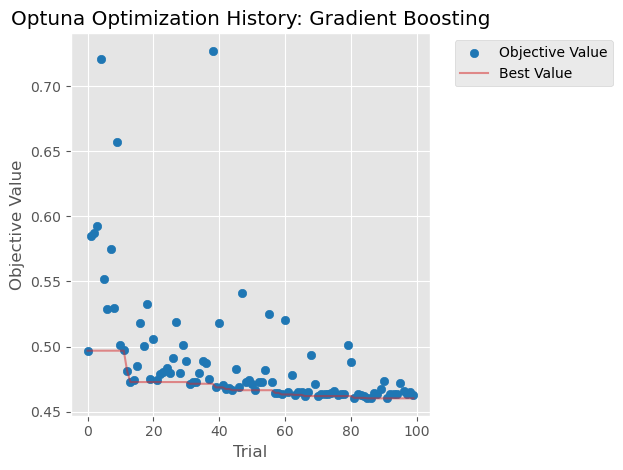

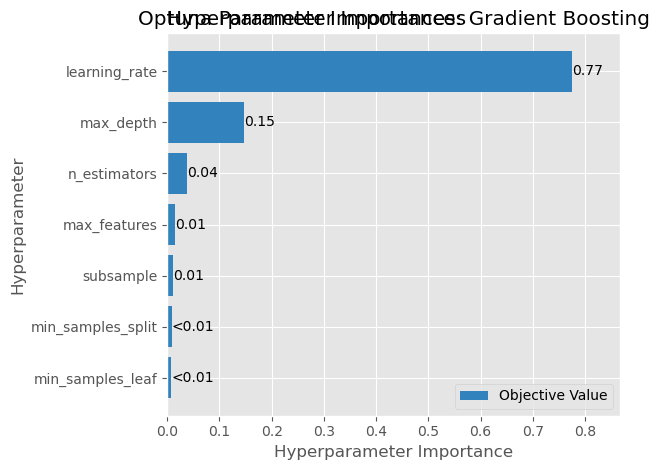

In [14]:
fig = plot_optimization_history(study)
plt.title('Optuna Optimization History: Gradient Boosting')
plt.tight_layout()
plt.show()

fig = plot_param_importances(study)
plt.title('Optuna Parameter Importances: Gradient Boosting')
plt.tight_layout()
plt.show()

## 8. Compare the best Grid, Random, and Optuna models
The table compares the best mean 5-fold CV RMSE from each search. These are model-selection scores and may be optimistic because the same CV process selected the best configuration. For an unbiased final performance estimate, reserve a separate test set before tuning.

In [12]:
best_models = pd.DataFrame([
    {'Search': 'GridSearchCV — Random Forest', 'Best CV RMSE': grid_best_rmse, 'Best parameters': str(grid_search.best_params_)},
    {'Search': 'RandomizedSearchCV — Random Forest', 'Best CV RMSE': random_best_rmse, 'Best parameters': str(random_search.best_params_)},
    {'Search': 'Optuna — Gradient Boosting', 'Best CV RMSE': optuna_best_rmse, 'Best parameters': str(study.best_params)}
]).sort_values('Best CV RMSE').reset_index(drop=True)
display(best_models.style.format({'Best CV RMSE': '{:.4f}'}))
winner = best_models.iloc[0]
print(f"Lowest observed CV RMSE: {winner['Search']} ({winner['Best CV RMSE']:.4f})")

,Search,Best CV RMSE,Best parameters
0,Optuna — Gradient Boosting,0.4603,"{'n_estimators': 293, 'learning_rate': 0.12779766780298235, 'max_depth': 5, 'min_samples_split': 8, 'min_samples_leaf': 6, 'subsample': 0.6642075670549351, 'max_features': None}"
1,RandomizedSearchCV — Random Forest,0.4964,"{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 8, 'model__n_estimators': 161}"
2,GridSearchCV — Random Forest,0.5005,"{'model__max_depth': 25, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}"


Lowest observed CV RMSE: Optuna — Gradient Boosting (0.4603)
